# Weekly Sales Forecasting: 45 Walmart Stores

**Goal.** Forecast each store's sales 8 weeks ahead and compare a seasonal naive baseline, ETS, ARIMA, an ETS+ARIMA average and gradient boosting.

**Validation.** Models are chosen on three rolling-origin backtests inside the training period. A single final 8-week holdout (2012-09-07 to 2012-10-26) is scored once and is not used for any choice.

**Read the results with care.** All three backtests and the holdout fall outside November and December, and the holdout is only 8 weeks long. The results say nothing about holiday-peak performance, and small gaps between the top models may not be robust.

**Sections:** 1 Data, 2 Quality checks, 3 Seasonality, 4 Split, 5 Models, 6 ARIMA shortlist, 7 Backtests, 8 Holdout, 9 Gradient boosting, 10 Error analysis, 11 Prediction intervals, 12 Interval plot, 13 Conclusions.

## 1. Load the data
Weekly sales for 45 stores, 2010-02-05 to 2012-10-26: 143 weeks each, 6,435 rows, no missing values. Dates are dd-mm-yyyy. The file is expected at `data/Walmart_Sales.csv`.

In [1]:
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")

df = pd.read_csv("data/Walmart_Sales.csv")
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)      # dates are dd-mm-yyyy
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

print(df.shape, df["Store"].nunique(), "stores")
print(df["Date"].min(), "to", df["Date"].max())
print(df.isna().sum().sum(), "missing values")

(6435, 8) 45 stores
2010-02-05 00:00:00 to 2012-10-26 00:00:00
0 missing values


### Environment used for the results below
Python 3.14.0, pandas 3.0.6, numpy 2.5.4, scikit-learn 1.9.1, statsmodels 0.15.0, matplotlib 3.11.2. These versions are pinned in `requirements.txt`.

In [2]:
import sys, sklearn, statsmodels
print("python", sys.version.split()[0])
for m in [pd, np, sklearn, statsmodels, plt.matplotlib]:
    print(m.__name__, m.__version__)

python 3.14.0
pandas 3.0.6
numpy 2.5.4
sklearn 1.9.1
statsmodels 0.15.0
matplotlib 3.11.2


## 2. Data-quality checks
Checks for duplicate store-weeks, negative sales and gaps between weeks, then flags unusual weeks (more than 3 robust standard deviations from the store's median) and tests whether the biggest sales weeks carry the holiday flag.

**What it shows**
- No duplicates or negative sales, and every gap is exactly 7 days.
- 269 store-weeks are unusual, and 89% of them fall in November and December, so they are mostly consistent with holiday peaks. I kept them, because removing them would delete the demand a forecaster has to predict.
- Three of the five biggest total-sales weeks (2010-12-24, 2011-12-23, 2010-12-17) have `Holiday_Flag = 0`. The flag misses most pre-Christmas weeks, so it is a weak signal.
- This exploration uses the full period, including the later test weeks. It informs understanding only and feeds no model.

In [3]:
print("duplicate store-weeks:", df.duplicated(["Store", "Date"]).sum())
print("negative sales:", (df["Weekly_Sales"] < 0).sum())
print("date gaps per store (days):", df.groupby("Store")["Date"].apply(lambda s: s.diff().dropna().dt.days.unique().tolist()).explode().unique())

# outliers: weeks more than 3 robust SDs from the store's median
med = df.groupby("Store")["Weekly_Sales"].transform("median")
mad = df.groupby("Store")["Weekly_Sales"].transform(lambda s: (s - s.median()).abs().median())
out = df[(df["Weekly_Sales"] - med).abs() > 3 * 1.4826 * mad]
print("outlier weeks:", len(out))
print("share in Nov-Dec:", round(out["Date"].dt.month.isin([11, 12]).mean(), 2))

# are the biggest sales weeks flagged as holidays?
top = df.groupby("Date")["Weekly_Sales"].sum().nlargest(5)
flags = df.drop_duplicates("Date").set_index("Date")["Holiday_Flag"].loc[top.index]
print(pd.DataFrame({"total_sales": top, "Holiday_Flag": flags}))

duplicate store-weeks: 0
negative sales: 0
date gaps per store (days): [7]
outlier weeks: 269
share in Nov-Dec: 0.89
            total_sales  Holiday_Flag
Date                                 
2010-12-24  80931415.60             0
2011-12-23  76998241.31             0
2011-11-25  66593605.26             1
2010-11-26  65821003.24             1
2010-12-17  61820799.85             0


## 3. Trend, seasonality and stationarity (all stores combined)
Plots total weekly sales, decomposes it with a 52-week period and runs an ADF stationarity test on the total.

**What to take from it**
- Yearly seasonality with year-end peaks is the dominant pattern, consistent with the Nov-Dec concentration of unusual weeks.
- Stationarity is checked per store in section 6, because the combined series can behave differently from individual stores.
- The data covers only about 2.7 years, so each week-of-year seasonal level is estimated from 2-3 observations. This limits how precisely any seasonal model can be fitted.

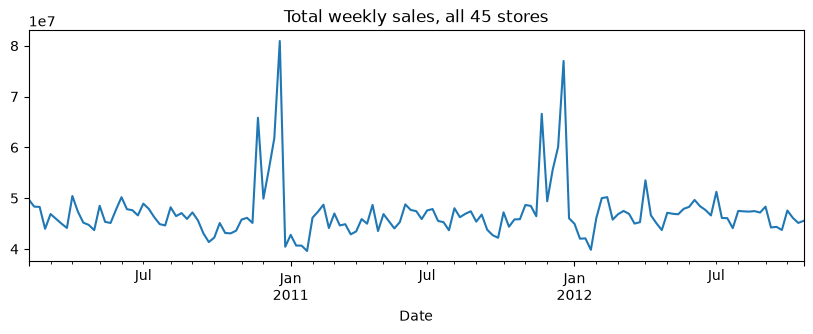

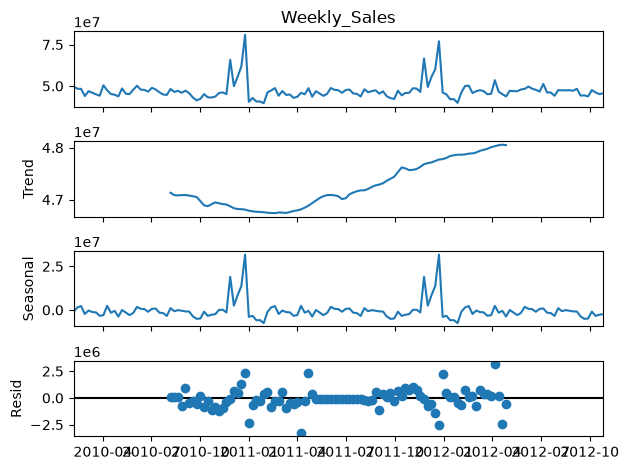

ADF p-value: 0.0
Holiday_Flag
0    1041256.0
1    1122888.0
Name: Weekly_Sales, dtype: float64


In [4]:
total = df.groupby("Date")["Weekly_Sales"].sum()
total.plot(figsize=(10, 3), title="Total weekly sales, all 45 stores")
plt.show()

seasonal_decompose(total, model="additive", period=52).plot()
plt.show()

print("ADF p-value:", round(adfuller(total)[1], 3))
print(df.groupby("Holiday_Flag")["Weekly_Sales"].mean().round(0))

## 4. Train / test split
Forecast horizon is 8 weeks. The last 8 weeks (2012-09-07 to 2012-10-26) are the final test set. The cutoff is 2012-08-31, leaving 135 training weeks per store. The test window contains only one holiday-flag week (Labor Day) and no Nov-Dec weeks.

In [5]:
H = 8                                                       # forecast horizon in weeks
cutoff = df["Date"].max() - pd.Timedelta(weeks=H)           # last 8 weeks = test set
n_train = int((df[df["Store"] == 1]["Date"] <= cutoff).sum())
print("cutoff:", cutoff.date(), "| training weeks per store:", n_train)

cutoff: 2012-08-31 | training weeks per store: 135


## 5. Forecasting models
- **Seasonal naive:** the same week last year.
- **ETS (additive Holt-Winters):**  exponential smoothing fitted with statsmodels’ ExponentialSmoothing, with additive 52-week seasonality, with and without a trend. “ETS” is used as shorthand throughout.
- **ARIMA:** fitted on the year-on-year difference (sales minus sales 52 weeks earlier); the forecast is last year's value plus the forecast change.

ETS needs at least two full seasonal cycles of data, which is why the backtests below use only three folds.

In [6]:
def fc_naive(y):
    return y[len(y) - 52 : len(y) - 52 + H]                # same weeks last year

def fc_ets(y, trend=None):
    return ExponentialSmoothing(y, trend=trend, seasonal="add", seasonal_periods=52).fit().forecast(H)

def fc_arima(y, order):
    z = y[52:] - y[:-52]                                    # seasonal difference
    m = ARIMA(z, order=order, trend="c" if order[1] == 0 else "n").fit()
    return y[len(y) - 52 : len(y) - 52 + H] + m.forecast(H)

## 6. Stationarity check and ARIMA order shortlist
Counts, per store, how many series pass the ADF test at different levels of differencing, then compares ARIMA orders by AIC summed across stores on training data. AIC is only comparable between models with the same `d`.

**What it shows**
- Stationary stores (of 45): 38 raw, 27 after the seasonal difference, 43 after an additional regular difference.
- Among `d=1` models, ARIMA(0,1,2) has the lowest AIC (90,337) and ARIMA(0,1,1) is nearly tied (90,342). Among `d=0`, ARIMA(1,0,1) is best (91,466). The `d=0` and `d=1` AIC values cannot be compared with each other.
- **AIC is used only to shortlist.** The final choice is made on the backtests in the next section, where ARIMA(0,1,1) (4.3% WAPE) edged out (0,1,2) (4.4%). It is also the simpler model.
- This search used all 135 training weeks, which overlap the backtest windows. Section 6b repeats it on pre-backtest data only.
- A second stationarity test (KPSS) is in 6a. It agrees that the seasonal difference alone is not enough and that one more regular difference makes almost every store stationary.

In [7]:
raw_p, seas_p, seas_reg_p = [], [], []
for store, g in df.groupby("Store"):
    y = g[g["Date"] <= cutoff]["Weekly_Sales"].values
    z = y[52:] - y[:-52]
    raw_p.append(adfuller(y)[1])
    seas_p.append(adfuller(z)[1])
    seas_reg_p.append(adfuller(np.diff(z))[1])
print("Stationary stores out of 45 (ADF p < 0.05):")
print("  raw series:                    ", sum(p < 0.05 for p in raw_p))
print("  after seasonal difference:     ", sum(p < 0.05 for p in seas_p))
print("  after seasonal + regular diff: ", sum(p < 0.05 for p in seas_reg_p))

# AIC is only comparable between models with the same d
results = []
for p, d, q in itertools.product([0, 1, 2, 3], [0, 1], [0, 1, 2]):
    total_aic = 0
    for store, g in df.groupby("Store"):
        y = g[g["Date"] <= cutoff]["Weekly_Sales"].values
        z = y[52:] - y[:-52]
        total_aic += ARIMA(z, order=(p, d, q), trend="c" if d == 0 else "n").fit().aic
    results.append({"p": p, "d": d, "q": q, "train_AIC": round(total_aic)})
print(pd.DataFrame(results).sort_values(["d", "train_AIC"]).to_string(index=False))

Stationary stores out of 45 (ADF p < 0.05):
  raw series:                     38
  after seasonal difference:      27
  after seasonal + regular diff:  43
 p  d  q  train_AIC
 1  0  1      91466
 1  0  2      91510
 2  0  2      91527
 2  0  1      91529
 3  0  2      91541
 3  0  1      91552
 2  0  0      91569
 3  0  0      91587
 1  0  0      91601
 0  0  2      91806
 0  0  1      91839
 0  0  0     104935
 0  1  2      90337
 0  1  1      90342
 1  1  1      90367
 1  1  2      90382
 2  1  1      90388
 2  1  2      90404
 3  1  1      90422
 3  1  2      90436
 3  1  0      90734
 2  1  0      90968
 1  1  0      91247
 0  1  0      91958


### 6a. Second stationarity test (KPSS)
ADF assumes a unit root and tries to reject it. KPSS assumes stationarity and tries to reject that. Running both checks whether the drop from 38 to 27 stationary stores in section 6 is just a weakness of one test. Counts are stores out of 45, using training weeks.

| Series | Points per store | ADF says stationary | KPSS says stationary | Both agree |
|---|---|---|---|---|
| Raw | 135 | 38 | 26 | 26 |
| Seasonal difference | 83 | 27 | 18 | 14 |
| Seasonal + regular difference | 82 | 43 | 44 | 42 |

**What it shows**
- Both tests find fewer stationary stores after the seasonal difference alone (ADF 38 to 27, KPSS 26 to 18), so the drop is not only ADF's low power. On the raw series ADF probably treats the strong seasonal cycle as mean-reverting, which would explain why it is more generous there.
- After the seasonal difference alone, many stores still look non-stationary under both tests, probably because year-on-year growth keeps drifting. I did not test that.
- After one more regular difference, both tests agree for 42 of 45 stores. That supports `d=1`, which matches the backtests, where ARIMA(0,1,1) beat ARIMA(1,0,1).
- With 82-83 points per store, both tests have limited power, so this is a guide, not a proof.

In [8]:
from statsmodels.tsa.stattools import kpss

rows = []
for label, make in [("raw", lambda y: y),
                    ("seasonal difference", lambda y: y[52:] - y[:-52]),
                    ("seasonal + regular difference", lambda y: np.diff(y[52:] - y[:-52]))]:
    adf_ok = kpss_ok = both = 0
    for store, g in df.groupby("Store"):
        y = g[g["Date"] <= cutoff]["Weekly_Sales"].values
        x = make(y)
        a = adfuller(x)[1] < 0.05                              # ADF rejects a unit root -> stationary
        k = kpss(x, regression="c", nlags="auto")[1] > 0.05    # KPSS does not reject stationarity -> stationary
        adf_ok += a; kpss_ok += k; both += (a and k)
    rows.append({"series": label, "points per store": len(x),
                 "ADF says stationary": adf_ok, "KPSS says stationary": kpss_ok, "both agree": both})
print(pd.DataFrame(rows).to_string(index=False))

                       series  points per store  ADF says stationary  KPSS says stationary  both agree
                          raw               135                   38                    26          26
          seasonal difference                83                   27                    18          14
seasonal + regular difference                82                   43                    44          42


### 6b. AIC check using only pre-backtest data
The AIC search in section 6 used all 135 training weeks, so it saw the weeks later used to score the backtests. This repeats it on the first 111 weeks only (the earliest backtest origin), so no backtest window is seen. AIC values are lower than before because there are fewer observations.

**What it shows**
- Among `d=1` models, ARIMA(0,1,1) now has the lowest AIC (63,832), ahead of (0,1,2) (63,859) and (1,1,1) (63,866). Among `d=0`, (1,0,1) is still best (64,959).
- The order chosen for the backtests is therefore also the best `d=1` order on data no backtest has seen, so the overlap did not affect the choice.

In [9]:
# Repeat the AIC search using ONLY the first 111 weeks (the earliest backtest origin),
# so none of the backtest answer weeks are seen.
first_origin = n_train - 24
aic_early = []
for p, d, q in itertools.product([0, 1, 2, 3], [0, 1], [0, 1, 2]):
    total_aic = 0
    for store, g in df.groupby("Store"):
        y = g["Weekly_Sales"].values[:first_origin]
        z = y[52:] - y[:-52]
        total_aic += ARIMA(z, order=(p, d, q), trend="c" if d == 0 else "n").fit().aic
    aic_early.append({"p": p, "d": d, "q": q, "AIC_first_111_weeks": round(total_aic)})
print(pd.DataFrame(aic_early).sort_values(["d", "AIC_first_111_weeks"]).to_string(index=False))

 p  d  q  AIC_first_111_weeks
 1  0  1                64959
 1  0  0                64995
 2  0  0                65013
 2  0  1                65022
 1  0  2                65027
 2  0  2                65043
 3  0  0                65063
 3  0  1                65081
 3  0  2                65082
 0  0  1                65143
 0  0  2                65146
 0  0  0                73331
 0  1  1                63832
 0  1  2                63859
 1  1  1                63866
 1  1  2                63910
 2  1  1                63920
 2  1  2                63957
 3  1  1                63959
 3  1  2                63998
 3  1  0                64144
 2  1  0                64271
 1  1  0                64395
 0  1  0                64922


## 7. Rolling-origin backtests (model selection)
At each of three origins (8, 16 and 24 weeks before the cutoff) every model is trained on earlier data only and scores the next 8 weeks. Fold 1 is the most recent. The folds cover roughly 23 Mar-11 May, 18 May-6 Jul and 13 Jul-31 Aug 2012, so none includes November or December.

**What it shows**
- ETS without trend and the ETS+ARIMA average tie at 4.1% mean WAPE, ARIMA(0,1,1) and ETS with trend score 4.3%, and seasonal naive scores 5.9%.
- Adding a trend to ETS does not help.
- The gaps among the top models (about 0.2 points) are small for three folds, so these models are close rather than clearly ranked.
- Seasonal naive under-forecasts (mean bias -2.5%); the other models are close to zero.
- Eight candidates were compared on the same three folds, so the best backtest scores are slightly optimistic.
- Gradient boosting is scored on these same folds in section 9b.

In [10]:
origins = [n_train - 8 * k for k in range(1, 4)]            # 3 origins, all inside the training period

candidates = {
    "Seasonal naive":    fc_naive,
    "ETS no trend":      lambda y: fc_ets(y, None),
    "ETS + trend":       lambda y: fc_ets(y, "add"),
    "ARIMA(1,0,1)":      lambda y: fc_arima(y, (1, 0, 1)),
    "ARIMA(0,1,1)":      lambda y: fc_arima(y, (0, 1, 1)),
    "ARIMA(1,1,1)":      lambda y: fc_arima(y, (1, 1, 1)),
    "ARIMA(0,1,2)":      lambda y: fc_arima(y, (0, 1, 2)),
    "ETS+ARIMA average": lambda y: (fc_ets(y, None) + fc_arima(y, (0, 1, 1))) / 2,
}

# columns: sum of absolute errors, sum of actual sales, sum of signed errors
err = {name: np.zeros((len(origins), 3)) for name in candidates}

for store, g in df.groupby("Store"):
    values = g["Weekly_Sales"].values
    for i, o in enumerate(origins):
        y, truth = values[:o], values[o : o + H]            # train before o, score the next 8 weeks
        for name, f in candidates.items():
            fc = f(y)
            err[name][i] += [np.abs(truth - fc).sum(), truth.sum(), (fc - truth).sum()]

rows = []
for name, e in err.items():
    wape = e[:, 0] / e[:, 1]
    row = {"model": name}
    row.update({f"fold{i+1}": round(w, 3) for i, w in enumerate(wape)})   # fold1 = most recent
    row["mean_WAPE"] = round(wape.mean(), 3)
    row["mean_bias"] = round((e[:, 2] / e[:, 1]).mean(), 3)
    rows.append(row)
print(pd.DataFrame(rows).sort_values("mean_WAPE").to_string(index=False))

            model  fold1  fold2  fold3  mean_WAPE  mean_bias
     ETS no trend  0.032  0.038  0.052      0.041      0.002
ETS+ARIMA average  0.033  0.038  0.051      0.041      0.002
     ARIMA(0,1,1)  0.036  0.039  0.055      0.043      0.003
      ETS + trend  0.035  0.039  0.054      0.043      0.003
     ARIMA(1,1,1)  0.037  0.039  0.055      0.044      0.003
     ARIMA(0,1,2)  0.037  0.039  0.056      0.044      0.003
     ARIMA(1,0,1)  0.038  0.043  0.056      0.046     -0.006
   Seasonal naive  0.051  0.056  0.070      0.059     -0.025


## 8. Final holdout evaluation
The models chosen above are fitted on the 135 training weeks and scored once on the 8 held-out weeks. Bias is sum(forecast - actual) / sum(actual), so a negative value means under-forecasting.

**What it shows**
- WAPE: ensemble 2.6%, ETS 2.9%, ARIMA(0,1,1) 3.0%, seasonal naive 4.9%.
- Bias: ETS -2.0%, ensemble -0.8%, ARIMA +0.4%, seasonal naive -1.7%.
- Treat the ensemble as the best observed result on this window, not as proven superior. The 0.3-point gap to ETS comes from one 8-week window and may not be robust.
- The holdout errors are lower than the backtest errors for every model, which suggests this window is easier than the backtest windows.

In [11]:
actual = df[df["Date"] > cutoff][["Store", "Date", "Weekly_Sales"]].reset_index(drop=True)

rows = []
for store, g in df.groupby("Store"):
    y = g[g["Date"] <= cutoff]["Weekly_Sales"].values
    f_ets, f_arima = fc_ets(y, None), fc_arima(y, (0, 1, 1))
    rows.append(pd.DataFrame({
        "Store": store,
        "Date": g[g["Date"] > cutoff]["Date"].values,
        "fc_naive": fc_naive(y),
        "fc_ets": f_ets,
        "fc_arima": f_arima,
        "fc_ensemble": (f_ets + f_arima) / 2,
    }))
test = actual.merge(pd.concat(rows), on=["Store", "Date"])

def report(test, cols):
    out = []
    for col in cols:
        wape = (test["Weekly_Sales"] - test[col]).abs().sum() / test["Weekly_Sales"].sum()
        bias = (test[col] - test["Weekly_Sales"]).sum() / test["Weekly_Sales"].sum()
        out.append({"model": col, "WAPE": round(wape, 3), "bias": round(bias, 3)})
    return pd.DataFrame(out).to_string(index=False)

print(report(test, ["fc_naive", "fc_ets", "fc_arima", "fc_ensemble"]))

      model  WAPE   bias
   fc_naive 0.049 -0.017
     fc_ets 0.029 -0.020
   fc_arima 0.030  0.004
fc_ensemble 0.026 -0.008


## 9. Gradient boosting
One pooled model for all stores. Each store's sales are scaled by that store's average over training weeks only. Features: sales 8 weeks ago, sales 52 weeks ago, the average of the 4 weeks ending 8 weeks ago, week of year, month and the holiday flag. Every lag is at least 8 weeks old, which is the newest data available when forecasting 8 weeks ahead.

**What it shows**
- Holdout WAPE 4.5%, bias +1.2%, worse than ETS and ARIMA on the holdout.
- It is untuned and uses only six features. It is also a different kind of model (one pooled model that sees the holiday flag, versus one fit per store), so the comparison is indicative rather than a controlled test of "machine learning versus statistics".
- Sections 9b and 9c score it on the backtest folds and with MASE.

In [12]:
# lag features: only use sales that are at least 8 weeks old
g = df.groupby("Store")["Weekly_Sales"]
df["lag_8"] = g.shift(8)
df["lag_52"] = g.shift(52)
df["lag_8_avg4"] = g.shift(8).groupby(df["Store"]).transform(lambda s: s.rolling(4).mean())
df["weekofyear"] = df["Date"].dt.isocalendar().week.astype(int)
df["month"] = df["Date"].dt.month

# put all stores on the same scale, using TRAINING weeks only
store_mean = df[df["Date"] <= cutoff].groupby("Store")["Weekly_Sales"].mean().rename("store_mean")
df = df.drop(columns=["store_mean"], errors="ignore").join(store_mean, on="Store")
for c in ["lag_8", "lag_52", "lag_8_avg4"]:
    df[c + "_n"] = df[c] / df["store_mean"]
df["target_n"] = df["Weekly_Sales"] / df["store_mean"]

features = ["lag_8_n", "lag_52_n", "lag_8_avg4_n", "weekofyear", "month", "Holiday_Flag"]

train_gb = df[df["Date"] <= cutoff].dropna(subset=features)
test_gb = df[df["Date"] > cutoff].copy()

gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0)
gb.fit(train_gb[features], train_gb["target_n"])
test_gb["fc_gb"] = gb.predict(test_gb[features]) * test_gb["store_mean"]

test = test.drop(columns="fc_gb", errors="ignore").merge(test_gb[["Store", "Date", "fc_gb"]], on=["Store", "Date"])
print(report(test, ["fc_naive", "fc_ets", "fc_arima", "fc_ensemble", "fc_gb"]))

      model  WAPE   bias
   fc_naive 0.049 -0.017
     fc_ets 0.029 -0.020
   fc_arima 0.030  0.004
fc_ensemble 0.026 -0.008
      fc_gb 0.045  0.012


### 9b. Gradient boosting on the same backtest folds
At each of the three origins the model is retrained on earlier weeks only, with each store's scaling recomputed from the weeks before that origin, and scored on the next 8 weeks. The ETS and ARIMA rows reproduce the table in section 7 exactly.

**What it shows**
- Gradient boosting: 4.1%, 5.4% and 6.2% WAPE by fold, 5.2% on average, mean bias -1.2%.
- It beats seasonal naive (5.9%) but trails ETS and the ensemble (4.1%) in every fold.
- Backtest bias is -1.2% but holdout bias is +1.2%, so it has no consistent direction of error.
- This simple untuned version does not beat the statistical models on this data. That says nothing about machine learning in general.

In [13]:
df["wk"] = df.groupby("Store").cumcount()            # week number within each store
raw_lags = ["lag_8", "lag_52", "lag_8_avg4"]
gb_err = np.zeros((len(origins), 3))                 # same layout as `err`: abs error, actual total, signed error

for i, o in enumerate(origins):
    mean_f = (df[df["wk"] < o].groupby("Store")["Weekly_Sales"].mean().rename("mean_f"))   # scale from weeks before the origin only
    d_f = df[df["wk"] < o + H].join(mean_f, on="Store")
    for c in raw_lags:
        d_f[c + "_n"] = d_f[c] / d_f["mean_f"]
    d_f["target_n"] = d_f["Weekly_Sales"] / d_f["mean_f"]
    tr = d_f[d_f["wk"] < o].dropna(subset=features)
    te = d_f[d_f["wk"] >= o]
    m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0)
    m.fit(tr[features], tr["target_n"])
    fc = m.predict(te[features]) * te["mean_f"]
    truth = te["Weekly_Sales"]
    gb_err[i] = [np.abs(truth - fc).sum(), truth.sum(), (fc - truth).sum()]

err_all = {**err, "Gradient boosting": gb_err}
rows = []
for name, e in err_all.items():
    wape = e[:, 0] / e[:, 1]
    row = {"model": name}
    row.update({f"fold{i+1}": round(w, 3) for i, w in enumerate(wape)})
    row["mean_WAPE"] = round(wape.mean(), 3)
    row["mean_bias"] = round((e[:, 2] / e[:, 1]).mean(), 3)
    rows.append(row)
print(pd.DataFrame(rows).sort_values("mean_WAPE").to_string(index=False))

            model  fold1  fold2  fold3  mean_WAPE  mean_bias
     ETS no trend  0.032  0.038  0.052      0.041      0.002
ETS+ARIMA average  0.033  0.038  0.051      0.041      0.002
     ARIMA(0,1,1)  0.036  0.039  0.055      0.043      0.003
      ETS + trend  0.035  0.039  0.054      0.043      0.003
     ARIMA(1,1,1)  0.037  0.039  0.055      0.044      0.003
     ARIMA(0,1,2)  0.037  0.039  0.056      0.044      0.003
     ARIMA(1,0,1)  0.038  0.043  0.056      0.046     -0.006
Gradient boosting  0.041  0.054  0.062      0.052     -0.012
   Seasonal naive  0.051  0.056  0.070      0.059     -0.025


### 9c. MASE on the holdout
MASE is mean absolute error divided by each store's in-sample seasonal-naive error, taken from training weeks only.

**What it shows**
- Ensemble 0.455, ETS 0.504, ARIMA 0.523, gradient boosting 0.736, seasonal naive 0.787. The ranking matches WAPE.
- Values below 1 do not mean a model beats a typical naive forecast. The scale includes holiday peaks in the training weeks, while the holdout is a calm window, so every model, including seasonal naive, scores below 1.
- MASE weights every store equally, while WAPE weights by sales, so the gaps between models differ a little.

In [14]:
# MASE: error scaled by each store's in-sample seasonal-naive error (training weeks only)
def naive_scale(s):
    y = s.values
    return np.abs(y[52:] - y[:-52]).mean()

scale = df[df["Date"] <= cutoff].groupby("Store")["Weekly_Sales"].apply(naive_scale)
test["scale"] = test["Store"].map(scale)
for col in ["fc_naive", "fc_ets", "fc_arima", "fc_ensemble", "fc_gb"]:
    print(col, "MASE:", round(((test["Weekly_Sales"] - test[col]).abs() / test["scale"]).mean(), 3))

fc_naive MASE: 0.787
fc_ets MASE: 0.504
fc_arima MASE: 0.523
fc_ensemble MASE: 0.455
fc_gb MASE: 0.736


## 10. Error analysis
Actual vs forecast for three stores, WAPE by forecast week (1 = next week, 8 = eight weeks ahead), and the best and worst stores for ETS.

**What it shows**
- Store-level error varies a lot: store 35 is the hardest (about 7.1% WAPE) and store 10 the easiest (about 1.3%).
- The by-horizon table shows whether error grows with forecast distance on this window.

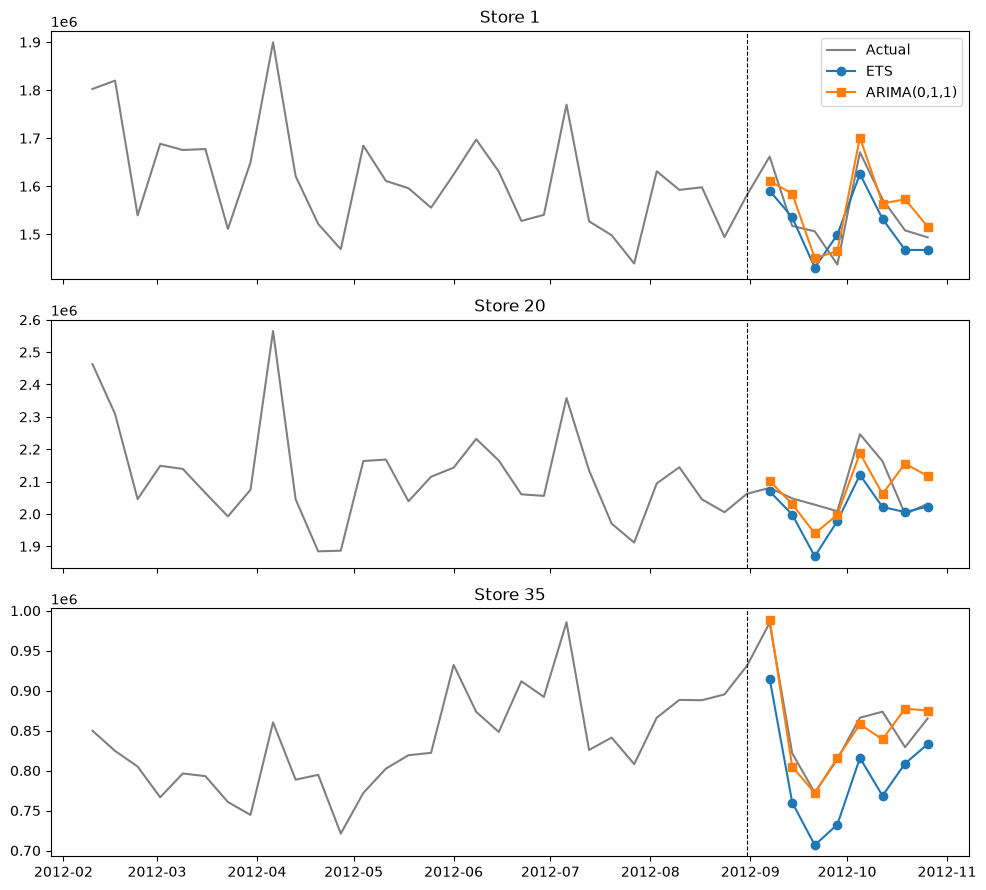

model    fc_arima  fc_ensemble  fc_ets  fc_naive
horizon                                         
1           0.032        0.032   0.036     0.060
2           0.022        0.017   0.018     0.039
3           0.023        0.029   0.039     0.056
4           0.023        0.023   0.029     0.054
5           0.029        0.021   0.027     0.048
6           0.028        0.031   0.040     0.053
7           0.045        0.027   0.021     0.046
8           0.037        0.023   0.023     0.037
worst stores:
 Store
44    0.043
18    0.043
38    0.043
9     0.044
35    0.071
dtype: float64
best stores:
 Store
10    0.013
30    0.014
4     0.014
34    0.016
27    0.019
dtype: float64


In [15]:
# 1) actual vs forecast for three stores
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, store in zip(axes, [1, 20, 35]):
    hist = df[(df["Store"] == store) & (df["Date"] > cutoff - pd.Timedelta(weeks=30))]
    t = test[test["Store"] == store]
    ax.plot(hist["Date"], hist["Weekly_Sales"], color="grey", label="Actual")
    ax.plot(t["Date"], t["fc_ets"], marker="o", label="ETS")
    ax.plot(t["Date"], t["fc_arima"], marker="s", label="ARIMA(0,1,1)")
    ax.axvline(cutoff, ls="--", color="black", lw=0.8)
    ax.set_title(f"Store {store}")
axes[0].legend()
plt.tight_layout()
plt.show()

# 2) error by forecast week (1 = next week ... 8 = eight weeks ahead)
test["horizon"] = test.groupby("Store")["Date"].rank().astype(int)
rows = []
for col in ["fc_naive", "fc_ets", "fc_arima", "fc_ensemble"]:
    for h, grp in test.groupby("horizon"):
        rows.append({"model": col, "horizon": h,
                     "WAPE": (grp["Weekly_Sales"] - grp[col]).abs().sum() / grp["Weekly_Sales"].sum()})
print(pd.DataFrame(rows).pivot(index="horizon", columns="model", values="WAPE").round(3))

# 3) best and worst stores for ETS
test["abs_err_ets"] = (test["Weekly_Sales"] - test["fc_ets"]).abs()
by_store = test.groupby("Store")["abs_err_ets"].sum() / test.groupby("Store")["Weekly_Sales"].sum()
print("worst stores:\n", by_store.sort_values().tail(5).round(3))
print("best stores:\n", by_store.sort_values().head(5).round(3))

### 10b. Seasonal-naive error by month
For every week that has a prior year (February 2011 onward), the error of "same week last year", grouped by calendar month. No model is fitted, so there is no test window to choose.

**What it shows**
- November (5.1%, 4 weeks) is typical. December (6.4%, 5 weeks) is slightly above the other months (4.5-5.9%), apart from April. Both are 2011 only.
- April is highest at 8.9%. Easter moved from 24 Apr 2011 to 8 Apr 2012, which a fixed 52-week shift cannot follow. April 2012 weeks also fall in backtest fold 3, the highest-error fold, so this may partly explain it.
- Thanksgiving and Christmas weeks line up under a 52-week shift, which is why the naive baseline is not worse in Q4.
- This is one Q4 and one baseline. It says nothing about ETS, ARIMA or the intervals at the peak.

In [16]:
d = df.copy()
d["naive"] = d.groupby("Store")["Weekly_Sales"].shift(52)      # same week last year
d = d.dropna(subset=["naive"])
d["abs_err"] = (d["Weekly_Sales"] - d["naive"]).abs()
tab = d.groupby(d["Date"].dt.month).agg(abs_err=("abs_err", "sum"),
                                         sales=("Weekly_Sales", "sum"),
                                         weeks=("Date", "nunique"))
tab["naive_WAPE"] = (tab["abs_err"] / tab["sales"]).round(3)
print(tab[["weeks", "naive_WAPE"]])

      weeks  naive_WAPE
Date                   
1         4       0.045
2         8       0.058
3         9       0.059
4         9       0.089
5         8       0.057
6         9       0.050
7         9       0.056
8         9       0.054
9         9       0.055
10        8       0.055
11        4       0.051
12        5       0.064


### 10c. Store 35
Store 35 has the highest ETS holdout error (7.1% WAPE). This looks at its size and volatility, its weekly errors and its year-on-year change.

**What it shows**
- It is the most volatile store in the training weeks (coefficient of variation 0.23, against a median of 0.13).
- ETS under-forecast it in all 8 holdout weeks, by 2% to 12% (about 7% on average). The error is one-directional, not noisy.
- Its holdout weeks were 8.3% above the same weeks last year, against a median of +2.7% across stores. Nine other stores had larger changes, so growth alone does not explain the gap.
- Section 10d tests the obvious explanation (growth that a no-trend ETS cannot follow). It does not hold up.

Store 35: mean weekly sales 923,657, coefficient of variation 0.23 (median across stores 0.13; rank 1 of 45, 1 = most volatile)
      Date  Weekly_Sales   fc_ets  ets_error_pct
2012-09-07      984833.0 915013.0           -7.0
2012-09-14      821569.0 760038.0           -8.0
2012-09-21      772303.0 706767.0           -8.0
2012-09-28      814100.0 732517.0          -10.0
2012-10-05      866064.0 815833.0           -6.0
2012-10-12      873643.0 768509.0          -12.0
2012-10-19      829285.0 808836.0           -2.0
2012-10-26      865138.0 833031.0           -4.0
Store 35: holdout weeks vs same weeks last year +8.3% (median across stores +2.7%; rank 10 of 45 by size of change)


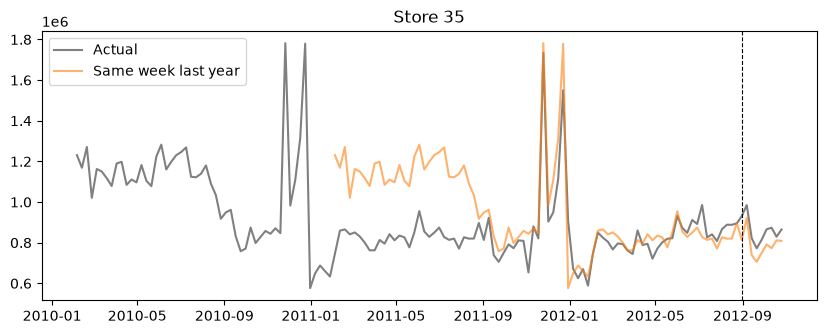

In [17]:
store = 35
s = df[df["Store"] == store].set_index("Date")["Weekly_Sales"]

# 1) size and volatility versus other stores (training weeks only)
tr = df[df["Date"] <= cutoff].groupby("Store")["Weekly_Sales"].agg(["mean", "std"])
tr["cv"] = tr["std"] / tr["mean"]
print(f"Store {store}: mean weekly sales {tr.loc[store, 'mean']:,.0f}, coefficient of variation "
      f"{tr.loc[store, 'cv']:.2f} (median across stores {tr['cv'].median():.2f}; "
      f"rank {int(tr['cv'].rank(ascending=False)[store])} of 45, 1 = most volatile)")

# 2) holdout: forecast error by week
t = test[test["Store"] == store][["Date", "Weekly_Sales", "fc_ets"]].copy()
t["ets_error_pct"] = ((t["fc_ets"] - t["Weekly_Sales"]) / t["Weekly_Sales"] * 100).round(1)
print(t.round(0).to_string(index=False))

# 3) holdout-week level versus the same weeks a year earlier, for every store
def yoy(g):
    m = g["Date"] > cutoff
    return g.loc[m, "Weekly_Sales"].mean() / g["Weekly_Sales"].shift(52)[m].mean() - 1
yoy_all = df.groupby("Store").apply(yoy)
print(f"Store {store}: holdout weeks vs same weeks last year {yoy_all[store]:+.1%} "
      f"(median across stores {yoy_all.median():+.1%}; rank {int(yoy_all.abs().rank(ascending=False)[store])} of 45 by size of change)")

# 4) history with last year's value overlaid
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(s.index, s.values, color="grey", label="Actual")
ax.plot(s.index, s.shift(52).values, color="tab:orange", alpha=0.6, label="Same week last year")
ax.axvline(cutoff, ls="--", color="black", lw=0.8)
ax.set_title(f"Store {store}"); ax.legend()
plt.show()

### 10d. Store 35: which models handle it, and what changed
Four models on store 35 alone (holdout and backtests), plus its year-on-year growth (8-week average sales against the same weeks a year earlier) next to the median store.

| Model | Holdout WAPE | Holdout bias | Backtest WAPE, folds 1 / 2 / 3 |
|---|---|---|---|
| Seasonal naive | 7.7% | -7.7% | 5.3% / 5.2% / 4.8% |
| ETS no trend | 7.1% | -7.1% | 5.6% / 5.7% / 4.4% |
| ETS + trend | 9.3% | -9.3% | 7.2% / 7.9% / 3.9% |
| ARIMA(0,1,1) | 1.8% | +0.1% | 4.8% / 8.4% / 4.1% |

**What it shows**
- Adding a trend makes the holdout worse (9.3%), so "growth that a no-trend ETS misses" is not the explanation.
- ARIMA(0,1,1) gets the holdout almost exactly (1.8%), while the models that copy last year's pattern (seasonal naive and ETS) under-forecast by 7-8%.
- The store's year-on-year growth swung widely: about -29% in early 2011 (median store about 0%), back to -2% by mid-2012, then +6% in August and +8% in October 2012, just as the holdout begins. Models anchored to last year's same weeks miss that turn. ARIMA is fitted on the year-on-year differences, so it follows it.
- This is not a persistent weakness in the backtests. ETS no-trend errors for this store (4.4-5.7%) are only somewhat above the all-store average (4.1%) with mixed bias, and ARIMA is worse than ETS in fold 2 (8.4%). One window where ARIMA happens to fit is not evidence that ARIMA is better for this store in general.
- The data cannot say what caused the swings in this store's sales. This is a diagnosis of what the models missed, not a cause.

In [18]:
store = 35
g = df[df["Store"] == store].reset_index(drop=True)
values = g["Weekly_Sales"].values
y_train = g.loc[g["Date"] <= cutoff, "Weekly_Sales"].values
truth = g.loc[g["Date"] > cutoff, "Weekly_Sales"].values

models = {"Seasonal naive": fc_naive,
          "ETS no trend": lambda y: fc_ets(y, None),
          "ETS + trend": lambda y: fc_ets(y, "add"),
          "ARIMA(0,1,1)": lambda y: fc_arima(y, (0, 1, 1))}

# 1) Holdout: does any model fit this store better, and is the bias the same sign?
print("Holdout, store", store)
for name, f in models.items():
    fc = f(y_train)
    print(f"  {name:15s} WAPE {np.abs(truth - fc).sum() / truth.sum():.3f} | bias {(fc - truth).sum() / truth.sum():+.3f}")

# 2) The three backtests: is the under-forecast persistent or only in the holdout?
print("Backtests (fold 1 = most recent), store", store)
for name, f in models.items():
    w, b = [], []
    for o in origins:
        t = values[o:o + H]; fc = f(values[:o])
        w.append(np.abs(t - fc).sum() / t.sum()); b.append((fc - t).sum() / t.sum())
    print(f"  {name:15s} WAPE by fold {np.round(w, 3)} | bias by fold {np.round(b, 3)}")

# 3) Growth: year-over-year change in 8-week average sales, store 35 versus the median store
wide = df.pivot(index="Date", columns="Store", values="Weekly_Sales").rolling(8).mean()
yoy_roll = wide / wide.shift(52) - 1
print(pd.DataFrame({"store 35": yoy_roll[store], "median store": yoy_roll.median(axis=1)}).dropna().iloc[::8].round(3))

Holdout, store 35
  Seasonal naive  WAPE 0.077 | bias -0.077
  ETS no trend    WAPE 0.071 | bias -0.071
  ETS + trend     WAPE 0.093 | bias -0.093
  ARIMA(0,1,1)    WAPE 0.018 | bias +0.001
Backtests (fold 1 = most recent), store 35
  Seasonal naive  WAPE by fold [0.053 0.052 0.048] | bias by fold [-0.052 -0.038  0.033]
  ETS no trend    WAPE by fold [0.056 0.057 0.044] | bias by fold [-0.014 -0.049  0.012]
  ETS + trend     WAPE by fold [0.072 0.079 0.039] | bias by fold [ 0.014 -0.079 -0.005]
  ARIMA(0,1,1)    WAPE by fold [0.048 0.084 0.041] | bias by fold [ 0.037 -0.084 -0.005]
            store 35  median store
Date                              
2011-03-25    -0.287        -0.021
2011-05-20    -0.285        -0.003
2011-07-15    -0.296         0.000
2011-09-09    -0.203         0.009
2011-11-04    -0.081         0.045
2011-12-30    -0.044         0.007
2012-02-24    -0.027         0.033
2012-04-20    -0.024         0.046
2012-06-15    -0.022         0.031
2012-08-10     0.063      

## 11. Prediction intervals
Interval = forecast x (1 + quantile of relative error), where the relative error (actual - forecast) / forecast comes from the three backtests. All stores share the same relative width. Coverage is then checked on the holdout, which was not used to build the intervals.

**What it shows**

| Model | Nominal | Holdout coverage | Width (% of forecast) |
|---|---|---|---|
| ETS | 50% | 57.5% | 5.9 |
| ETS | 80% | 88.9% | 12.5 |
| ETS | 90% | 96.9% | 17.1 |
| Ensemble | 50% | 61.7% | 5.9 |
| Ensemble | 80% | 93.1% | 12.2 |
| Ensemble | 90% | 98.1% | 17.5 |

- Coverage is above nominal at every level, so the intervals are conservative (wider than needed) on this window. A likely reason is that the backtest folds are more volatile than the calm holdout.
- Coverage alone can be inflated by wide intervals, which is why width is shown beside it.
- The holdout covers only 8 distinct weeks, and stores share the same shocks, so the coverage figures are weaker evidence than the 360 store-weeks suggest.
- Coverage was not tested on holiday peaks, so these intervals should not be assumed reliable there.
- Coverage by forecast week and one-sided checks of the upper bounds are in 11b.

In [19]:
def collect_cv_errors(forecast_fn):
    """Relative errors (actual - forecast) / forecast from the rolling-origin folds."""
    rel = []
    for store, g in df.groupby("Store"):
        values = g["Weekly_Sales"].values
        for o in origins:
            y, truth = values[:o], values[o : o + H]
            fc = forecast_fn(y)
            rel.append((truth - fc) / fc)
    return np.concatenate(rel)

def interval_check(forecast_fn, col, levels=(0.5, 0.8, 0.9)):
    rel = collect_cv_errors(forecast_fn)
    rows = []
    for L in levels:
        a = (1 - L) / 2
        q_lo, q_hi = np.quantile(rel, [a, 1 - a])
        pct = int(round(L * 100))
        test[f"{col}_lo{pct}"] = test[col] * (1 + q_lo)
        test[f"{col}_hi{pct}"] = test[col] * (1 + q_hi)
        inside = ((test["Weekly_Sales"] >= test[f"{col}_lo{pct}"]) &
                  (test["Weekly_Sales"] <= test[f"{col}_hi{pct}"])).mean()
        rows.append({"model": col, "nominal": L,
                     "test_coverage": round(inside, 3),
                     "width_pct_of_forecast": round((q_hi - q_lo) * 100, 1)})
    return pd.DataFrame(rows)

ets_cov = interval_check(lambda y: fc_ets(y, None), "fc_ets")
ens_cov = interval_check(lambda y: (fc_ets(y, None) + fc_arima(y, (0, 1, 1))) / 2, "fc_ensemble")
print(pd.concat([ets_cov, ens_cov]).to_string(index=False))

      model  nominal  test_coverage  width_pct_of_forecast
     fc_ets      0.5          0.575                    5.9
     fc_ets      0.8          0.889                   12.5
     fc_ets      0.9          0.969                   17.1
fc_ensemble      0.5          0.617                    5.9
fc_ensemble      0.8          0.931                   12.2
fc_ensemble      0.9          0.981                   17.5


### 11b. Coverage by forecast week, and a planning illustration
**Coverage by forecast week.** The interval width is the same at every horizon by construction (one pooled quantile). ETS 80% coverage ranges from 71% (week 6) to 98% (weeks 2 and 7), and the ensemble from 87% to 100%. There is no steady decline with horizon. Each week has only 45 store-weeks that share the same calendar week, so these swings are noisy and should not be over-read.

**One-sided checks.**

| Plan | ETS: actual above plan | ETS: average (plan - actual) / actual | Ensemble: actual above plan | Ensemble: average (plan - actual) / actual |
|---|---|---|---|---|
| Point forecast | 71.9% | -1.9% | 58.3% | -0.9% |
| 80% upper bound | 10.3% | +4.2% | 5.6% | +5.2% |
| 90% upper bound | 2.8% | +7.1% | 1.4% | +8.6% |

- The upper bounds are close to nominal: the 80% interval's upper end (nominal 10% above) was exceeded in 10.3% of ETS store-weeks, and the 90% interval's (nominal 5%) in 2.8%.
- ETS two-sided coverage was 88.9%, so only about 1% of actuals fell below the lower bound. The over-coverage comes almost entirely from the lower side, which likely reflects larger drops in the backtest folds than anything in the holdout.
- **Planning illustration.** Planning above the point forecast cuts how often actual demand exceeds the plan, but raises the average overshoot. ETS runs about 2% low on this window, so ordering to its point forecast would have fallen short in most store-weeks.
- "Above plan" counts any shortfall however small and is not a stockout rate. A real inventory evaluation needs stock levels, costs, lead times and service targets, which this data does not have. This is also a single calm 8-week window.

In [20]:
test["horizon"] = test.groupby("Store")["Date"].rank().astype(int)

for col in ["fc_ets", "fc_ensemble"]:
    inside = (test["Weekly_Sales"] >= test[f"{col}_lo80"]) & (test["Weekly_Sales"] <= test[f"{col}_hi80"])
    print(col, "- 80% interval coverage by forecast week (width is the same at every week by construction):")
    print(inside.groupby(test["horizon"]).mean().round(3).to_string())

print()
for col in ["fc_ets", "fc_ensemble"]:
    for label, plan in [("point forecast", test[col]),
                        ("80% upper bound", test[f"{col}_hi80"]),
                        ("90% upper bound", test[f"{col}_hi90"])]:
        exceed = (test["Weekly_Sales"] > plan).mean()
        gap = ((plan - test["Weekly_Sales"]) / test["Weekly_Sales"]).mean()
        print(f"{col} | plan = {label:16s} | actual above plan: {exceed:.1%} of store-weeks | average (plan - actual)/actual: {gap:+.1%}")

fc_ets - 80% interval coverage by forecast week (width is the same at every week by construction):
horizon
1    0.800
2    0.978
3    0.911
4    0.889
5    0.911
6    0.711
7    0.978
8    0.933
fc_ensemble - 80% interval coverage by forecast week (width is the same at every week by construction):
horizon
1    0.867
2    1.000
3    0.956
4    0.911
5    0.956
6    0.911
7    0.911
8    0.933

fc_ets | plan = point forecast   | actual above plan: 71.9% of store-weeks | average (plan - actual)/actual: -1.9%
fc_ets | plan = 80% upper bound  | actual above plan: 10.3% of store-weeks | average (plan - actual)/actual: +4.2%
fc_ets | plan = 90% upper bound  | actual above plan: 2.8% of store-weeks | average (plan - actual)/actual: +7.1%
fc_ensemble | plan = point forecast   | actual above plan: 58.3% of store-weeks | average (plan - actual)/actual: -0.9%
fc_ensemble | plan = 80% upper bound  | actual above plan: 5.6% of store-weeks | average (plan - actual)/actual: +5.2%
fc_ensemble | plan = 

### 11c. Per-store interval widths (sensitivity check)
Each store's interval width is scaled by its typical backtest error (the average absolute relative error over its 24 backtest forecasts), using one pooled quantile of the standardised errors. Stores are grouped into thirds by that backtest error. The headline intervals in section 11 are unchanged. All figures are for the ETS 80% interval on the holdout.

| Store group | Pooled coverage | Scaled coverage | Pooled width | Scaled width |
|---|---|---|---|---|
| Easy stores | 94.2% | 84.2% | 12.5% | 9.0% |
| Middle | 89.2% | 89.2% | 12.5% | 12.0% |
| Hard stores | 83.3% | 91.7% | 12.5% | 15.9% |
| Overall | 88.9% | 88.3% | 12.5% | 12.3% |

**What it shows**
- Same average width and about the same overall coverage, but the scaled version matches width to difficulty: narrower for easy stores, wider for hard ones.
- The spread in coverage across groups shrinks from 10.9 points (94.2% to 83.3%) to 7.5 points (84.2% to 91.7%), and every group stays above 80%.
- Each group is 15 stores over 8 weeks that share the same shocks, and each store's scale rests on only 24 errors, so this is suggestive, not conclusive. The pooled intervals remain the main result.

In [21]:
stores = sorted(df["Store"].unique())
rel = collect_cv_errors(lambda y: fc_ets(y, None)).reshape(len(stores), -1)   # row = store, 24 backtest errors each
scale_s = pd.Series(np.abs(rel).mean(axis=1), index=stores)                    # each store's typical relative error
z = rel / scale_s.values[:, None]                                              # standardised errors, pooled

def scaled_bounds(level, col="fc_ets"):
    a = (1 - level) / 2
    q_lo, q_hi = np.quantile(z, [a, 1 - a])
    s_ = test["Store"].map(scale_s)
    return test[col] * (1 + s_ * q_lo), test[col] * (1 + s_ * q_hi)

lo, hi = scaled_bounds(0.8)
test["group"] = test["Store"].map(pd.qcut(scale_s, 3, labels=["easy stores", "middle", "hard stores"]))
res = pd.DataFrame({
    "group": test["group"],
    "pooled_covered": (test["Weekly_Sales"] >= test["fc_ets_lo80"]) & (test["Weekly_Sales"] <= test["fc_ets_hi80"]),
    "scaled_covered": (test["Weekly_Sales"] >= lo) & (test["Weekly_Sales"] <= hi),
    "pooled_width_pct": (test["fc_ets_hi80"] - test["fc_ets_lo80"]) / test["fc_ets"] * 100,
    "scaled_width_pct": (hi - lo) / test["fc_ets"] * 100,
})
print(res.groupby("group", observed=True).mean().round(3))
print("overall:\n", res.drop(columns="group").mean().round(3))

             pooled_covered  scaled_covered  pooled_width_pct  \
group                                                           
easy stores           0.942           0.842            12.476   
middle                0.892           0.892            12.476   
hard stores           0.833           0.917            12.476   

             scaled_width_pct  
group                          
easy stores             9.026  
middle                 12.043  
hard stores            15.928  
overall:
 pooled_covered       0.889
scaled_covered       0.883
pooled_width_pct    12.476
scaled_width_pct    12.332
dtype: float64


## 12. Forecast with 80% interval
ETS forecast and 80% interval against actual sales for three stores.

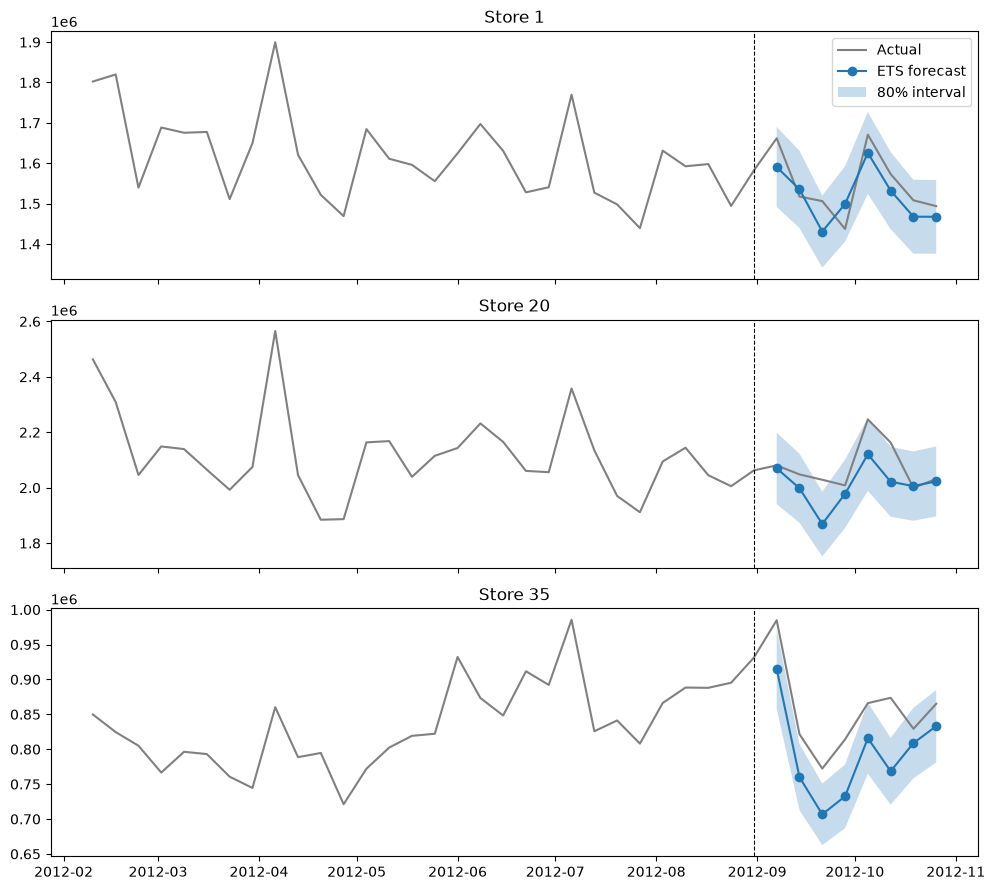

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, store in zip(axes, [1, 20, 35]):
    hist = df[(df["Store"] == store) & (df["Date"] > cutoff - pd.Timedelta(weeks=30))]
    t = test[test["Store"] == store]
    ax.plot(hist["Date"], hist["Weekly_Sales"], color="grey", label="Actual")
    ax.plot(t["Date"], t["fc_ets"], marker="o", label="ETS forecast")
    ax.fill_between(t["Date"], t["fc_ets_lo80"], t["fc_ets_hi80"], alpha=0.25, label="80% interval")
    ax.axvline(cutoff, ls="--", color="black", lw=0.8)
    ax.set_title(f"Store {store}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 13. Conclusions and limitations

**Findings**
- On three backtests, ETS and the ETS+ARIMA average are the best statistical models (4.1% WAPE against 5.9% for seasonal naive). On the final holdout the ensemble scores 2.6% against 4.9% for seasonal naive.
- ETS, ARIMA and the ensemble are close to each other. The ensemble is the best observed result, not a proven winner.
- Gradient boosting scored 4.5% on the holdout and 5.2% in the backtests (seasonal naive 5.9%, ETS 4.1%). This simple untuned version beat seasonal naive in the backtests but not ETS or ARIMA.
- Empirical prediction intervals over-cover on the holdout (80% interval: 88.9% for ETS, 93.1% for the ensemble), so they are conservative on this window. The over-coverage comes almost entirely from the lower bound; the upper bounds are close to nominal (section 11b). Scaling each store's width by its backtest error gives narrower intervals for easy stores and wider ones for hard stores at the same average width (section 11c); the headline intervals are unchanged.

**Limitations**
- No backtest or holdout window includes November or December, so nothing here shows how the models handle holiday peaks. Only one earlier Q4 (2010) exists as history, which is too short to fit ETS for a Q4 2011 test. Seasonal naive was not unusually inaccurate in Nov-Dec 2011 (section 10b), but that says nothing about ETS, ARIMA or the intervals at the peak.
- The holdout is one 8-week window. The backtest numbers are slightly optimistic because the best model was chosen from eight candidates on the same folds, and the holdout is likely easier than typical windows.
- Gradient boosting is untuned and uses few features; the main intervals use the same relative width for every store (a per-store scaled version is a sensitivity check in 11c).
- The hardest store (35) was under-forecast in all 8 holdout weeks. Seasonal naive and ETS missed a sharp turn in the store's year-on-year growth, which ARIMA followed (section 10d). The data cannot say what caused the swings in that store's sales.
- Temperature, fuel price, CPI and unemployment were not used because their future values are unknown at forecast time.
- This is a predictive project. It does not estimate what causes sales to change.

**How forecasts and intervals could inform planning (illustrative)**
- A point forecast is expected demand; the interval gives a plausible range. Planning above the point forecast trades fewer shortfalls against more excess stock, and the upper end of an interval is one reference level for that choice.
- Bias matters for the direction of error. ETS under-forecast by about 2% on the holdout, which means ordering to its point forecast would on average run slightly short. In the holdout, actual sales exceeded the ETS point forecast in 72% of store-weeks but exceeded its 80% upper bound in 10% (section 11b), at the cost of planning about 4% above actual on average.
- This data can show forecast error and interval behaviour. It cannot show stockout rates or the right safety stock, because it has no inventory levels, costs, lead times or service-level targets. Interval coverage is not a stockout rate. An actual inventory evaluation would need that data.